In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

import sys
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import optax

from functools import partial
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter, NullFormatter

root_path = Path.cwd()
sys.path.append(str(root_path / 'toolbox'))

from configs import ModelConfig, ModelState, ModelParams, SubmodelParams, Params
from models import L63, L63_incomplete
from submodels import SimpleFC
from toolbox.simu_tools import rollout
from toolbox.grad_tools.config_grad_approx import setup_grad_approx
from toolbox.loss_tools import loss_fn
from toolbox.pytree_tools import params_partition, params_recombine
from toolbox.grad_tools.baseline_grad_methods import compute_exact_bptt, compute_tbptt
from toolbox.grad_tools.proposed_grad_approx_methods import compute_zero_order, compute_reuse
from toolbox.eval_perf_tools import relative_l2_error, cosine_similarity, xla_temp_bytes, time_call_min

print("JAX is using:", jax.devices())

JAX is using: [CudaDevice(id=0)]


In [2]:
# ── Config ────────────────────────────────────────────────────────────────────
cfg = ModelConfig(
    solver = "Tsit5",
    dt0    = 0.01,
    hybrid = True, 
    dtype  = jnp.float32,
)

# ── Models ────────────────────────────────────────────────────────────────────
l63   = L63(cfg)
l63_incomplete = L63_incomplete(cfg)

# ── Submodel ──────────────────────────────────────────────────────────────────
submodel = SimpleFC(input_dim=3, hidden_dim=32, output_dim=3)
theta    = submodel.init_theta(seed=0, dtype= cfg.dtype)

# ── Params ────────────────────────────────────────────────────────────────────
model_p = ModelParams()                               # sigma, rho, beta
submodel_p   = SubmodelParams(theta=theta)            # NN weights
params  = Params(model=model_p, submodel=submodel_p)

# ── State ─────────────────────────────────────────────────────────────────────
state = ModelState.init(dtype= cfg.dtype)             # x=8, y=0, z=30, t=None

# ── Quick check ───────────────────────────────────────────────────────────────
print("ModelConfig:     ", cfg)
print("State:      ", state.x, "| t:", state.t)
print("ModelParams:", params.model)
print("Theta dict keys: ", list(theta['params'].keys()))

ModelConfig:      ModelConfig(solver='Tsit5', dt0=0.01, hybrid=True, dtype=<class 'jax.numpy.float32'>)
State:       [ 8.  0. 30.] | t: None
ModelParams: ModelParams(sigma=10.0, rho=28.0, beta=2.6666666666666665)
Theta dict keys:  ['Dense_0', 'Dense_1']


In [3]:
rollout_jit = jax.jit(
    rollout,
    static_argnames=("step_fn", "nsteps", "save_traj")
)

N_STEPS_SPINUP= 500 
N_STEPS = 1500

step_fn_l63 = lambda s, p: l63.step(s, p)
step_fn_incomplete_l63 = lambda s, p: l63_incomplete.step(s, p)
step_fn_hybrid_l63 = lambda s, p: l63_incomplete.step(s, p, submodel=submodel)

state0,_= rollout(step_fn_l63, state, params, nsteps= N_STEPS_SPINUP, save_traj=False) # Spinup 

_, traj_true = rollout(step_fn_l63, state0, params, nsteps= N_STEPS, save_traj=True)

_, traj_incomplete = rollout(step_fn_incomplete_l63, state0, params, nsteps=N_STEPS, save_traj=True)

_, traj_incomplete_corr= rollout(step_fn_hybrid_l63, state0, params, nsteps=N_STEPS, save_traj=True)

traj_incomplete_corr: 712 non-finite step(s) (untrained NN correction diverged) -- excluded from shared axis limits


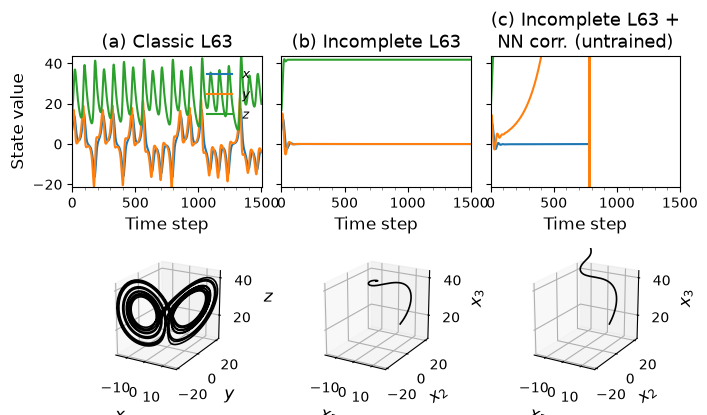

In [4]:
label_size = 12
title_size = 13
tick_size = 10

fig = plt.figure(figsize=(7, 4))

bounded_data = jnp.vstack([
    traj_true,
    traj_incomplete,
])

xmin, ymin, zmin = jnp.min(bounded_data, axis=0)
xmax, ymax, zmax = jnp.max(bounded_data, axis=0)

ymin_ts = jnp.min(bounded_data)
ymax_ts = jnp.max(bounded_data)

n_corr_nonfinite = int((~jnp.isfinite(traj_incomplete_corr)).any(axis=1).sum())
if n_corr_nonfinite:
    print(f"traj_incomplete_corr: {n_corr_nonfinite} non-finite step(s) "
          f"(untrained NN correction diverged) -- excluded from shared axis limits")

# ==================================================
# (a) True time series
# ==================================================
ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(traj_true[:, 0], label=r"$x$")
ax1.plot(traj_true[:, 1], label=r"$y$")
ax1.plot(traj_true[:, 2], label=r"$z$")

ax1.set_title("(a) Classic L63", fontsize=title_size)
ax1.set_ylabel("State value", fontsize=label_size)
ax1.set_xlabel("Time step", fontsize=label_size)

ax1.set_xlim(0, traj_true.shape[0])
ax1.set_ylim(ymin_ts, ymax_ts)

ax1.tick_params(labelsize=tick_size)
ax1.legend(frameon=False, fontsize=9)

# ==================================================
# (b) Incomplete time series
# ==================================================
ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(traj_incomplete[:, 0])
ax2.plot(traj_incomplete[:, 1])
ax2.plot(traj_incomplete[:, 2])

ax2.set_title("(b) Incomplete L63", fontsize=title_size)
ax2.set_xlabel("Time step", fontsize=label_size)

ax2.set_xlim(0, traj_true.shape[0])
ax2.set_ylim(ymin_ts, ymax_ts)

ax2.tick_params(labelsize=tick_size)
ax2.tick_params(labelleft=False)

# ==================================================
# (c) Incomplete + untrained NN correction
# ==================================================
ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(traj_incomplete_corr[:, 0])
ax3.plot(traj_incomplete_corr[:, 1])
ax3.plot(traj_incomplete_corr[:, 2])

ax3.set_title(
    "(c) Incomplete L63 +\nNN corr. (untrained)",
    fontsize=title_size
)

ax3.set_xlabel("Time step", fontsize=label_size)

ax3.set_xlim(0, traj_true.shape[0])
ax3.set_ylim(ymin_ts, ymax_ts)

ax3.tick_params(labelsize=tick_size)
ax3.tick_params(labelleft=False)

# ==================================================
# Minor ticks on time series
# ==================================================
for ax in [ax1, ax2, ax3]:
    ax.xaxis.set_minor_locator(MultipleLocator(100))
    ax.tick_params(
        which="minor",
        length=2,
        color="gray"
    )

# ==================================================
# (d) True attractor
# ==================================================
ax4 = fig.add_subplot(2, 3, 4, projection="3d")

ax4.plot(
    traj_true[:, 0],
    traj_true[:, 1],
    traj_true[:, 2],
    color="black",
    lw=1.2
)

ax4.set_xlabel(r"$x$", fontsize=label_size)
ax4.set_ylabel(r"$y$", fontsize=label_size)
ax4.set_zlabel(r"$z$", fontsize=label_size)

ax4.tick_params(labelsize=tick_size)

# ==================================================
# (e) Incomplete attractor
# ==================================================
ax5 = fig.add_subplot(2, 3, 5, projection="3d")

ax5.plot(
    traj_incomplete[:, 0],
    traj_incomplete[:, 1],
    traj_incomplete[:, 2],
    color="black",
    lw=1.2
)

ax5.set_xlabel(r"$x_1$", fontsize=label_size)
ax5.set_ylabel(r"$x_2$", fontsize=label_size)
ax5.set_zlabel(r"$x_3$", fontsize=label_size)

ax5.tick_params(labelsize=tick_size)

# ==================================================
# (f) Incomplete + NN correction attractor
# ==================================================
ax6 = fig.add_subplot(2, 3, 6, projection="3d")

ax6.plot(
    traj_incomplete_corr[:, 0],
    traj_incomplete_corr[:, 1],
    traj_incomplete_corr[:, 2],
    color="black",
    lw=1.2
)

ax6.set_xlabel(r"$x_1$", fontsize=label_size)
ax6.set_ylabel(r"$x_2$", fontsize=label_size)
ax6.set_zlabel(r"$x_3$", fontsize=label_size)

ax6.tick_params(labelsize=tick_size)

for ax in [ax4, ax5, ax6]:
    ax.view_init(elev=20, azim=-60)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_zlim(zmin, zmax)

    ax.set_box_aspect([
        xmax - xmin,
        ymax - ymin,
        zmax - zmin
    ])

plt.tight_layout()

# plt.savefig(
#     "true_vs_incomplete_L63.pdf",
#     format="pdf",
#     bbox_inches="tight"
# )

# plt.savefig(
#     "true_vs_incomplete_L63.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()


## Gradient fidelity & computational cost (paper Fig. 2)

Same protocol as `l63_benchmark_trained_said.py`, run with the toolbox gradient functions
(the ZO / Reuse double-scan VJP of `proposed_grad_approx_methods.py`):

* reference: classic L63 from $(1, 2, 3)$, 5000-step spin-up, 10000 steps, first 8000 used;
  `N_ICS` initial conditions drawn with `np.random.seed(42)`,
* every approximate gradient is compared with **exact BPTT** on the same IC, for two submodels:
  random initialization (seed 42) and the submodel trained on a 10-step forecast loss ("optimal parameters"),
* metrics: cosine similarity (and relative L2 error) w.r.t. the exact gradient, **peak memory ratio**
  (XLA temporary buffers of the compiled executable / exact) and **speedup** (best of 15 timed calls, exact / method),
  reported as median and IQR over the ICs.

Degree of approximation $\alpha$ (smaller = more aggressive): for **TBPTT** $\alpha$ is the window length,
for **Zero-order / Reuse** $\alpha$ is the number of chunks (anchors), with the anchor at the chunk midpoint
`K//2` (`bias_dir="downstream"`). Pairs with $N \bmod \alpha \neq 0$ or $\alpha = N$ are skipped.

In [5]:
# ── Benchmark configuration ───────────────────────────────────────────────────
N_LIST     = [10, 20, 40, 80, 120, 160, 200]   # unrolled steps N
ALPHA_LIST = [1, 2, 4, 10, 20, 40]             # degree of approximation alpha
N_ICS      = 50                                # initial conditions per (N, alpha)
BIAS_DIR   = "downstream"                      # anchor at the chunk midpoint K//2

# alpha -> number of chunks handed to setup_grad_approx
METHODS = {
    "TBPTT":      (compute_tbptt,      lambda N, a: N // a),   # alpha = window length
    "Zero-order": (compute_zero_order, lambda N, a: a),        # alpha = number of chunks
    "Reuse":      (compute_reuse,      lambda N, a: a),        # alpha = number of chunks
}

def is_valid(N, a):
    return N % a == 0 and a != N

# Short-term forecast training of the "optimal" submodel
TRAIN_HORIZON    = 10
TRAIN_BATCH_SIZE = 64
TRAIN_ITERS      = 3000
TRAIN_LR         = 1e-3
TRAIN_SEED       = 0

RESULTS_DIR  = Path("results/grad_approx_method_convergence_performance")
TRAINED_PATH = Path("trained_models/fidelity_benchmark_submodel.pkl")
PLOT_PATH    = "pyplots/gradient_methods_fidelity_performance_l63"
RETRAIN      = True       # False -> reuse TRAINED_PATH if it exists

step_fn_l63        = lambda s, p: l63.step(s, p)
step_fn_hybrid_l63 = lambda s, p: l63_incomplete.step(s, p, submodel=submodel)

grad_mask = Params(
    model=ModelParams(sigma=False, rho=False, beta=False),
    submodel=SubmodelParams(theta=jax.tree_util.tree_map(lambda _: True, params.submodel.theta)),
)

### Reference dataset & initial conditions

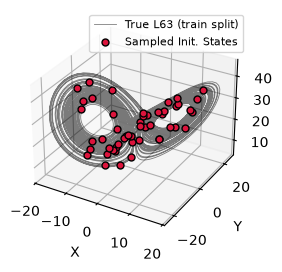

In [6]:
state_ref0 = ModelState.init(x=1.0, y=2.0, z=3.0, dtype=cfg.dtype)
state_spun, _ = rollout(step_fn_l63, state_ref0, params, nsteps=5000)
_, traj_ref = rollout(step_fn_l63, state_spun, params, nsteps=10000, save_traj=True)
traj_ref   = traj_ref[1:]          # the 10000 post-spin-up states
train_traj = traj_ref[:8000]

np.random.seed(42)
ic_indices = np.random.choice(len(train_traj) - max(N_LIST) - 1, N_ICS, replace=False)

# --- Plotting  ---
LEGEND_SIZE = 8
fig = plt.figure(figsize=(5, 3))
ax = fig.add_subplot(111, projection='3d')
ax.plot(train_traj[:, 0], train_traj[:, 1], train_traj[:, 2],
        color='black', alpha=0.5, linewidth=0.6, label='True L63 (train split)')
ics = train_traj[ic_indices]
ax.scatter(ics[:, 0], ics[:, 1], ics[:, 2],
           color='crimson', s=25, edgecolors='black', depthshade=False, zorder=5, label='Sampled Init. States')
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend(loc='upper right', fontsize=LEGEND_SIZE)
plt.show()

### Submodel at "optimal parameters"

The NN correction is trained with exact BPTT on a `TRAIN_HORIZON`-step forecast MSE
(random windows of the training trajectory, Adam), as in Said's benchmark.

  iter     0/3000  10-step forecast MSE = 6.213e+00
  iter   150/3000  10-step forecast MSE = 1.010e+00
  iter   300/3000  10-step forecast MSE = 5.491e-02
  iter   450/3000  10-step forecast MSE = 1.819e-02
  iter   600/3000  10-step forecast MSE = 5.306e-03
  iter   750/3000  10-step forecast MSE = 2.525e-03
  iter   900/3000  10-step forecast MSE = 1.729e-03
  iter  1050/3000  10-step forecast MSE = 9.325e-04
  iter  1200/3000  10-step forecast MSE = 8.483e-04
  iter  1350/3000  10-step forecast MSE = 4.329e-04
  iter  1500/3000  10-step forecast MSE = 2.904e-04
  iter  1650/3000  10-step forecast MSE = 2.568e-04
  iter  1800/3000  10-step forecast MSE = 2.215e-04
  iter  1950/3000  10-step forecast MSE = 1.458e-04
  iter  2100/3000  10-step forecast MSE = 2.497e-04
  iter  2250/3000  10-step forecast MSE = 1.434e-04
  iter  2400/3000  10-step forecast MSE = 1.285e-04
  iter  2550/3000  10-step forecast MSE = 2.132e-04
  iter  2700/3000  10-step forecast MSE = 1.726e-04
  iter  2850

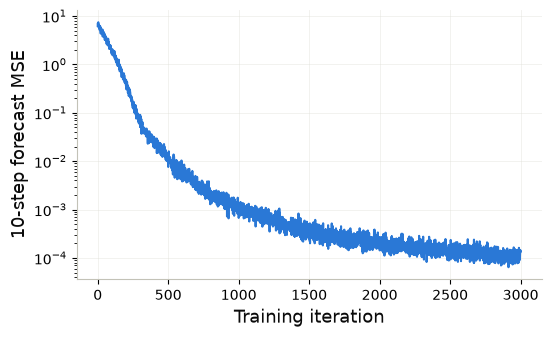

In [7]:
def train_submodel_forecast(params_init, traj, horizon=TRAIN_HORIZON, batch_size=TRAIN_BATCH_SIZE,
                            n_iters=TRAIN_ITERS, lr=TRAIN_LR, seed=TRAIN_SEED):
    traj = np.asarray(traj)
    windows = np.stack([traj[i:i + horizon + 1] for i in range(len(traj) - horizon)])

    dynamic_p, static_p = params_partition(params_init, grad_mask)
    gcfg = setup_grad_approx(nsteps=horizon, n_anchors=1)
    grad_single = partial(compute_exact_bptt, step_fn=step_fn_hybrid_l63, loss_fn=loss_fn,
                          grad_approx_cfg=gcfg, grad_mask=grad_mask)
    optimizer = optax.adam(lr)

    @jax.jit
    def train_step(d_p, opt_state, Y):
        full_p = params_recombine(d_p, static_p)
        losses, grads = jax.vmap(lambda y: grad_single(ModelState(x=y[0], t=None), full_p, y))(Y)
        grads = jax.tree_util.tree_map(lambda g: g.mean(0), grads)
        updates, opt_state = optimizer.update(grads, opt_state, d_p)
        return optax.apply_updates(d_p, updates), opt_state, losses.mean()

    rng = np.random.default_rng(seed)
    d_p, opt_state, history = dynamic_p, optimizer.init(dynamic_p), []
    print_every = max(1, n_iters // 20)
    for it in range(n_iters):
        Y = jnp.asarray(windows[rng.choice(len(windows), size=batch_size, replace=False)])
        d_p, opt_state, loss = train_step(d_p, opt_state, Y)
        history.append(float(loss))
        if it % print_every == 0 or it == n_iters - 1:
            print(f"  iter {it:5d}/{n_iters}  {horizon}-step forecast MSE = {history[-1]:.3e}")
    return params_recombine(d_p, static_p), np.array(history)


params_untrained = Params(model=model_p, submodel=SubmodelParams(theta=submodel.init_theta(seed=42, dtype=cfg.dtype)))

if RETRAIN or not TRAINED_PATH.exists():
    params_trained, train_history = train_submodel_forecast(params_untrained, train_traj)
    TRAINED_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(TRAINED_PATH, "wb") as f:
        pickle.dump({"params": params_trained, "history": train_history}, f, protocol=pickle.HIGHEST_PROTOCOL)
else:
    with open(TRAINED_PATH, "rb") as f:
        _saved = pickle.load(f)
    params_trained, train_history = _saved["params"], _saved["history"]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(train_history, color='#2a78d6', linewidth=1.5)
ax.set_yscale('log')
ax.set_xlabel("Training iteration", fontsize=13, color='#0b0b0b')
ax.set_ylabel(f"{TRAIN_HORIZON}-step forecast MSE", fontsize=13, color='#0b0b0b')
ax.grid(True, which='major', linestyle='-', alpha=0.5, linewidth=0.6, color='#e1e0d9')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
plt.show()

### Run the benchmark

In [8]:
def run_fidelity_benchmark(params_by_tag, traj, ic_indices, N_list, alpha_list, methods, bias_dir=BIAS_DIR):
    """Per (method, alpha, N, IC): cosine similarity / relative L2 error of the approximate gradient
    w.r.t. exact BPTT, peak-memory ratio and speedup over exact BPTT. Every executable is compiled
    once and evaluated for each parameter set of `params_by_tag`. Returns one row per IC."""
    p_ref = next(iter(params_by_tag.values()))

    def compile_grad(fn, gcfg, N):
        f = jax.jit(partial(fn, step_fn=step_fn_hybrid_l63, loss_fn=loss_fn, grad_approx_cfg=gcfg,
                            loss_eval="running", grad_mask=grad_mask))
        return f.lower(ModelState(x=traj[0], t=None), p_ref, traj[:N + 1]).compile()

    records, n_loss_mismatch = [], 0
    for N in N_list:
        print(f"N = {N}")
        exact_comp = compile_grad(compute_exact_bptt, setup_grad_approx(nsteps=N, n_anchors=1), N)
        exact_mem  = xla_temp_bytes(exact_comp)
        inputs = [(ModelState(x=traj[i], t=None), traj[i:i + N + 1]) for i in ic_indices]
        exact  = {tag: [time_call_min(exact_comp, s, p, y) for s, y in inputs]
                  for tag, p in params_by_tag.items()}

        for a in alpha_list:
            if not is_valid(N, a):
                continue
            for name, (fn, n_chunks_of) in methods.items():
                gcfg = setup_grad_approx(nsteps=N, n_anchors=n_chunks_of(N, a), bias_dir=bias_dir)
                comp = compile_grad(fn, gcfg, N)
                mem_ratio = xla_temp_bytes(comp) / exact_mem
                for tag, p in params_by_tag.items():
                    for ic, ((s, y), ((loss_ex, g_ex), t_ex)) in enumerate(zip(inputs, exact[tag])):
                        (loss, g), t = time_call_min(comp, s, p, y)
                        if not np.isclose(float(loss), float(loss_ex), rtol=1e-3, atol=1e-5):
                            n_loss_mismatch += 1
                        records.append(dict(
                            tag=tag, method=name, alpha=a, N=N, ic=ic,
                            cos=cosine_similarity(g_ex, g), rel_l2=relative_l2_error(g_ex, g),
                            mem_ratio=mem_ratio, speedup=t_ex / t,
                        ))
                print(f"  alpha = {a:3d}  {name:10s}  mem ratio = {mem_ratio:.3f}")
                del comp
        del exact_comp

    print(f"\nLoss consistency check: {'OK' if n_loss_mismatch == 0 else f'{n_loss_mismatch} mismatch(es)'}")
    return pd.DataFrame(records)


df_fidelity = run_fidelity_benchmark(
    params_by_tag={"untrained": params_untrained, "trained": params_trained},
    traj=train_traj, ic_indices=ic_indices,
    N_list=N_LIST, alpha_list=ALPHA_LIST, methods=METHODS,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_fidelity.to_pickle(RESULTS_DIR / f"fidelity_benchmark_{N_ICS}_ics.pkl")

N = 10
  alpha =   1  TBPTT       mem ratio = 0.261
  alpha =   1  Zero-order  mem ratio = 0.665
  alpha =   1  Reuse       mem ratio = 0.614
  alpha =   2  TBPTT       mem ratio = 0.778
  alpha =   2  Zero-order  mem ratio = 0.791
  alpha =   2  Reuse       mem ratio = 0.710
N = 20
  alpha =   1  TBPTT       mem ratio = 0.189
  alpha =   1  Zero-order  mem ratio = 0.481
  alpha =   1  Reuse       mem ratio = 0.445
  alpha =   2  TBPTT       mem ratio = 0.564
  alpha =   2  Zero-order  mem ratio = 0.573
  alpha =   2  Reuse       mem ratio = 0.514
  alpha =   4  TBPTT       mem ratio = 0.621
  alpha =   4  Zero-order  mem ratio = 0.573
  alpha =   4  Reuse       mem ratio = 0.514
  alpha =  10  TBPTT       mem ratio = 0.805
  alpha =  10  Zero-order  mem ratio = 0.573
  alpha =  10  Reuse       mem ratio = 0.514
N = 40
  alpha =   1  TBPTT       mem ratio = 0.117
  alpha =   1  Zero-order  mem ratio = 0.304
  alpha =   1  Reuse       mem ratio = 0.282
  alpha =   2  TBPTT       mem rat

In [9]:
summary = (df_fidelity
           .groupby(["tag", "method", "alpha", "N"])[["cos", "rel_l2", "mem_ratio", "speedup"]]
           .median()
           .unstack("tag"))
pd.set_option("display.max_rows", 200)
summary.round(4)

cos            rel_l2           mem_ratio            \
tag                  trained untrained trained untrained   trained untrained   
method     alpha N                                                             
Reuse      1     10   0.9988    0.9997  0.0619    0.0611    0.6145    0.6145   
                 20   0.9946    0.9974  0.1349    0.1252    0.4451    0.4451   
                 40   0.9522    0.9736  0.4143    0.2576    0.2818    0.2818   
                 80   0.6245    0.9768  0.9568    0.2882    0.1651    0.1651   
                 120  0.4828    0.9895  0.9841    0.3012    0.1293    0.1293   
                 160  0.1914    0.9952  1.0013    0.2400    0.1073    0.1073   
                 200  0.2833    0.9959  1.1049    0.2110    0.0940    0.0940   
           2     10   0.9999    1.0000  0.0154    0.0103    0.7096    0.7096   
                 20   0.9991    0.9996  0.0476    0.0350    0.5140    0.5140   
                 40   0.9959    0.9977  0.1367    0.0710    0.3243    0.3243   
                 80   0.7285    0.9786  0.8727    0.2954    0.1801    0.1801   
                 120  0.4846    0.9752  0.9921    0.2935    0.1319    0.1319   
                 160  0.2174    0.9903  1.0139    0.2785    0.1053    0.1053   
                 200  0.5225    0.9937  0.9993    0.1693    0.0876    0.0876   
           4     20   0.9999    1.0000  0.0116    0.0059    0.5140    0.5140   
                 40   0.9994    0.9999  0.0499    0.0180    0.3243    0.3243   
                 80   0.9941    0.9990  0.2198    0.0551    0.1801    0.1801   
                 120  0.9418    0.9971  0.6436    0.1141    0.1319    0.1319   
                 160  0.6270    0.9949  0.9279    0.1395    0.1033    0.1033   
                 200 -0.1970    0.9934  1.0394    0.1510    0.0860    0.0860   
           10    20   0.9998    0.9999  0.0236    0.0202    0.5140    0.5140   
                 40   0.9997    0.9999  0.0340    0.0160    0.3243    0.3243   
                 80   0.9997    1.0000  0.0514    0.0133    0.1801    0.1801   
                 120  0.9989    1.0000  0.0923    0.0137    0.1319    0.1319   
                 160  0.9969    0.9999  0.1854    0.0151    0.1033    0.1033   
                 200  0.9907    0.9998  0.3065    0.0208    0.0860    0.0860   
           20    40   0.9998    0.9999  0.0309    0.0164    0.3243    0.3243   
                 80   0.9998    1.0000  0.0435    0.0114    0.1801    0.1801   
                 120  0.9997    1.0000  0.0387    0.0094    0.1319    0.1319   
                 160  0.9997    1.0000  0.0541    0.0075    0.1033    0.1033   
                 200  0.9994    1.0000  0.0755    0.0066    0.0860    0.0860   
           40    80   0.9998    1.0000  0.0446    0.0112    0.1839    0.1839   
                 120  1.0000    1.0000  0.0078    0.0011    0.1346    0.1346   
                 160  0.9998    1.0000  0.0258    0.0077    0.1053    0.1053   
                 200  1.0000    1.0000  0.0208    0.0014    0.0876    0.0876   
TBPTT      1     10   0.9667    0.9782  0.8539    0.8576    0.2607    0.2607   
                 20   0.8860    0.9340  0.9371    0.9312    0.1888    0.1888   
                 40   0.5811    0.8710  0.9904    0.9642    0.1165    0.1165   
                 80   0.0787    0.8378  0.9994    0.9774    0.0620    0.0620   
                 120  0.0198    0.8964  1.0000    0.9855    0.0436    0.0436   
                 160 -0.2502    0.9012  1.0001    0.9890    0.0328    0.0328   
                 200 -0.2160    0.9469  1.0001    0.9916    0.0263    0.0263   
           2     10   0.9732    0.9826  0.7750    0.7799    0.7785    0.7785   
                 20   0.8929    0.9402  0.9055    0.8949    0.5639    0.5639   
                 40   0.5996    0.8769  0.9847    0.9456    0.3480    0.3480   
                 80   0.0971    0.8453  0.9992    0.9660    0.1852    0.1852   
                 120  0.0432    0.9031  0.9999    0.9782    0.1302    0.1302   
                 160 -0.2

### Plot

In [10]:
def plot_fidelity_benchmark(df, method_names=("TBPTT", "Zero-order", "Reuse"), perf_tag="trained",
                            suptitle=None, save_path=None):
    """Rows: methods. Columns: cosine similarity at initialization / at optimal parameters,
    peak memory ratio, speedup (median over ICs, shaded IQR). Cost columns use `perf_tag`."""
    # ── Style handles ───────────────────────────────────────
    xlabel_size = 22
    ylabel_size = 24
    title_size  = 24
    tick_size   = 20
    legend_size = 17
    linewidth   = 2.7
    markersize  = 11
    markeredgewidth = 1.8

    col_specs = [
        # (metric, tag, iqr band, y-scale, hline, fixed ylim, title)
        ("cos",       "untrained", True,  "linear", 1.0,  (-0.2, 1.2), "Cosine Similarity\n(at initialization)"),
        ("cos",       "trained",   True,  "linear", 1.0,  (-0.2, 1.2), "Cosine Similarity\n(optimal parameters)"),
        ("mem_ratio", perf_tag,    False, "linear", None, None,        "Peak Memory Ratio"),
        ("speedup",   perf_tag,    True,  "log2",   1.0,  None,        "Speedup"),
    ]
    n_rows, n_cols = len(method_names), len(col_specs)

    def summarize(metric, tag, method):
        g = df[(df.tag == tag) & (df.method == method)].groupby(["alpha", "N"])[metric]
        return pd.DataFrame({"med": g.median(), "p25": g.quantile(0.25), "p75": g.quantile(0.75)}).reset_index()

    stats = {(c, m): summarize(spec[0], spec[1], m) for c, spec in enumerate(col_specs) for m in method_names}

    # ── Global alpha → (color, marker) map, shared across every row ─────
    PALETTE = ['#2a78d6', '#1baf7a', '#eda100', '#008300',
               '#4a3aa7', '#e34948', '#e87ba4', '#eb6834']
    MARKERS = ['o', 's', 'D', '^', 'v', 'P', 'X', '*']
    all_alphas = sorted(df["alpha"].unique())
    colors  = {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(all_alphas)}
    markers = {a: MARKERS[i % len(MARKERS)] for i, a in enumerate(all_alphas)}

    # ── Global, equally-spaced N axis, shared across every row ───────────
    all_N_values = sorted(df["N"].unique())
    N_to_pos = {n: i for i, n in enumerate(all_N_values)}

    # ── Shared y-limits per column ────────────────────────────────
    col_ylims = {}
    for c, (metric, tag, band, scale, hline, fixed, _) in enumerate(col_specs):
        if fixed is not None:
            col_ylims[c] = fixed
            continue
        vals = np.concatenate([stats[(c, m)][["med", "p25", "p75"] if band else ["med"]].values.ravel()
                               for m in method_names])
        vals = vals[np.isfinite(vals) & (vals > 0)]
        if scale == "log2":
            lo, hi = min(vals.min(), 0.9), max(vals.max(), 1.1)
            pad = (np.log2(hi) - np.log2(lo)) * 0.08
            col_ylims[c] = (2 ** (np.log2(lo) - pad), 2 ** (np.log2(hi) + pad))
        else:
            pad = (vals.max() - vals.min()) * 0.08
            col_ylims[c] = (max(0.0, vals.min() - pad), vals.max() + pad)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
    axes = np.atleast_2d(axes)
    fig.patch.set_facecolor('white')
    if suptitle:
        fig.suptitle(suptitle, fontsize=title_size, fontweight='bold', y=1.02)

    for row_idx, method in enumerate(method_names):
        is_first_row, is_last_row = row_idx == 0, row_idx == n_rows - 1
        axes[row_idx, 0].set_ylabel(method, fontsize=ylabel_size, fontweight='bold',
                                    labelpad=10, rotation=90, ha='center', va='center', color='#0b0b0b')

        for c, (metric, tag, band, scale, hline, fixed, title) in enumerate(col_specs):
            ax = axes[row_idx, c]
            st = stats[(c, method)]
            for a in all_alphas:
                sub = st[st["alpha"] == a].set_index("N").reindex(all_N_values)
                if sub["med"].isna().all():
                    continue
                x = np.arange(len(all_N_values))
                ax.plot(x, sub["med"].values,
                        marker=markers[a], linewidth=linewidth, markersize=markersize,
                        markerfacecolor='#fcfcfb', markeredgecolor=colors[a],
                        markeredgewidth=markeredgewidth, color=colors[a], label=f"α={a}")
                if band:
                    ax.fill_between(x, sub["p25"].values, sub["p75"].values,
                                    alpha=0.12, color=colors[a], linewidth=0)

            # ── Axis styling ──
            ax.set_facecolor('white')
            if scale == "log2":
                ax.set_yscale('log', base=2)
                ax.yaxis.set_major_formatter(FormatStrFormatter('%.1fx'))
                ax.yaxis.set_minor_formatter(NullFormatter())
            ax.set_ylim(*col_ylims[c])
            if hline is not None:
                ax.axhline(hline, color='#898781', linestyle='--', linewidth=0.9, zorder=0)
            ax.set_xticks(range(len(all_N_values)))
            ax.set_xlim(-0.4, len(all_N_values) - 0.6)
            ax.tick_params(axis='x', which='major', length=6, width=1.0, colors='#0b0b0b')
            if is_last_row:
                ax.set_xticklabels(all_N_values, fontsize=tick_size, color='#0b0b0b',
                                   rotation=45, ha='right', rotation_mode='anchor')
                ax.set_xlabel("N (unrolled steps)", fontsize=xlabel_size, color='#0b0b0b')
            else:
                ax.set_xticklabels([])
            ax.tick_params(axis='y', which='both', labelsize=tick_size, colors='#0b0b0b')
            ax.grid(True, axis='y', which='major', linestyle='-', alpha=0.5, linewidth=0.6, color='#e1e0d9')
            ax.grid(True, axis='x', which='major', linestyle='-', alpha=0.5, linewidth=0.6, color='#e1e0d9')
            ax.set_axisbelow(True)
            ax.spines[['top', 'right']].set_visible(False)
            ax.spines[['left', 'bottom']].set_color('#c3c2b7')
            if is_first_row:
                ax.set_title(title, fontsize=title_size, pad=8, fontweight='bold', color='#0b0b0b')

    leg = axes[0, 0].legend(loc='lower right', title="Parameter α", fontsize=legend_size,
                            title_fontsize=legend_size, framealpha=0.7, handlelength=1.6, edgecolor='#c3c2b7')
    leg.get_frame().set_facecolor('#fcfcfb')

    fig.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.08, wspace=0.22, hspace=0.10)

    if save_path is not None:
        fig.savefig(f"{save_path}.pdf", bbox_inches="tight")
        fig.savefig(f"{save_path}.png", dpi=300, bbox_inches="tight")

    plt.show()

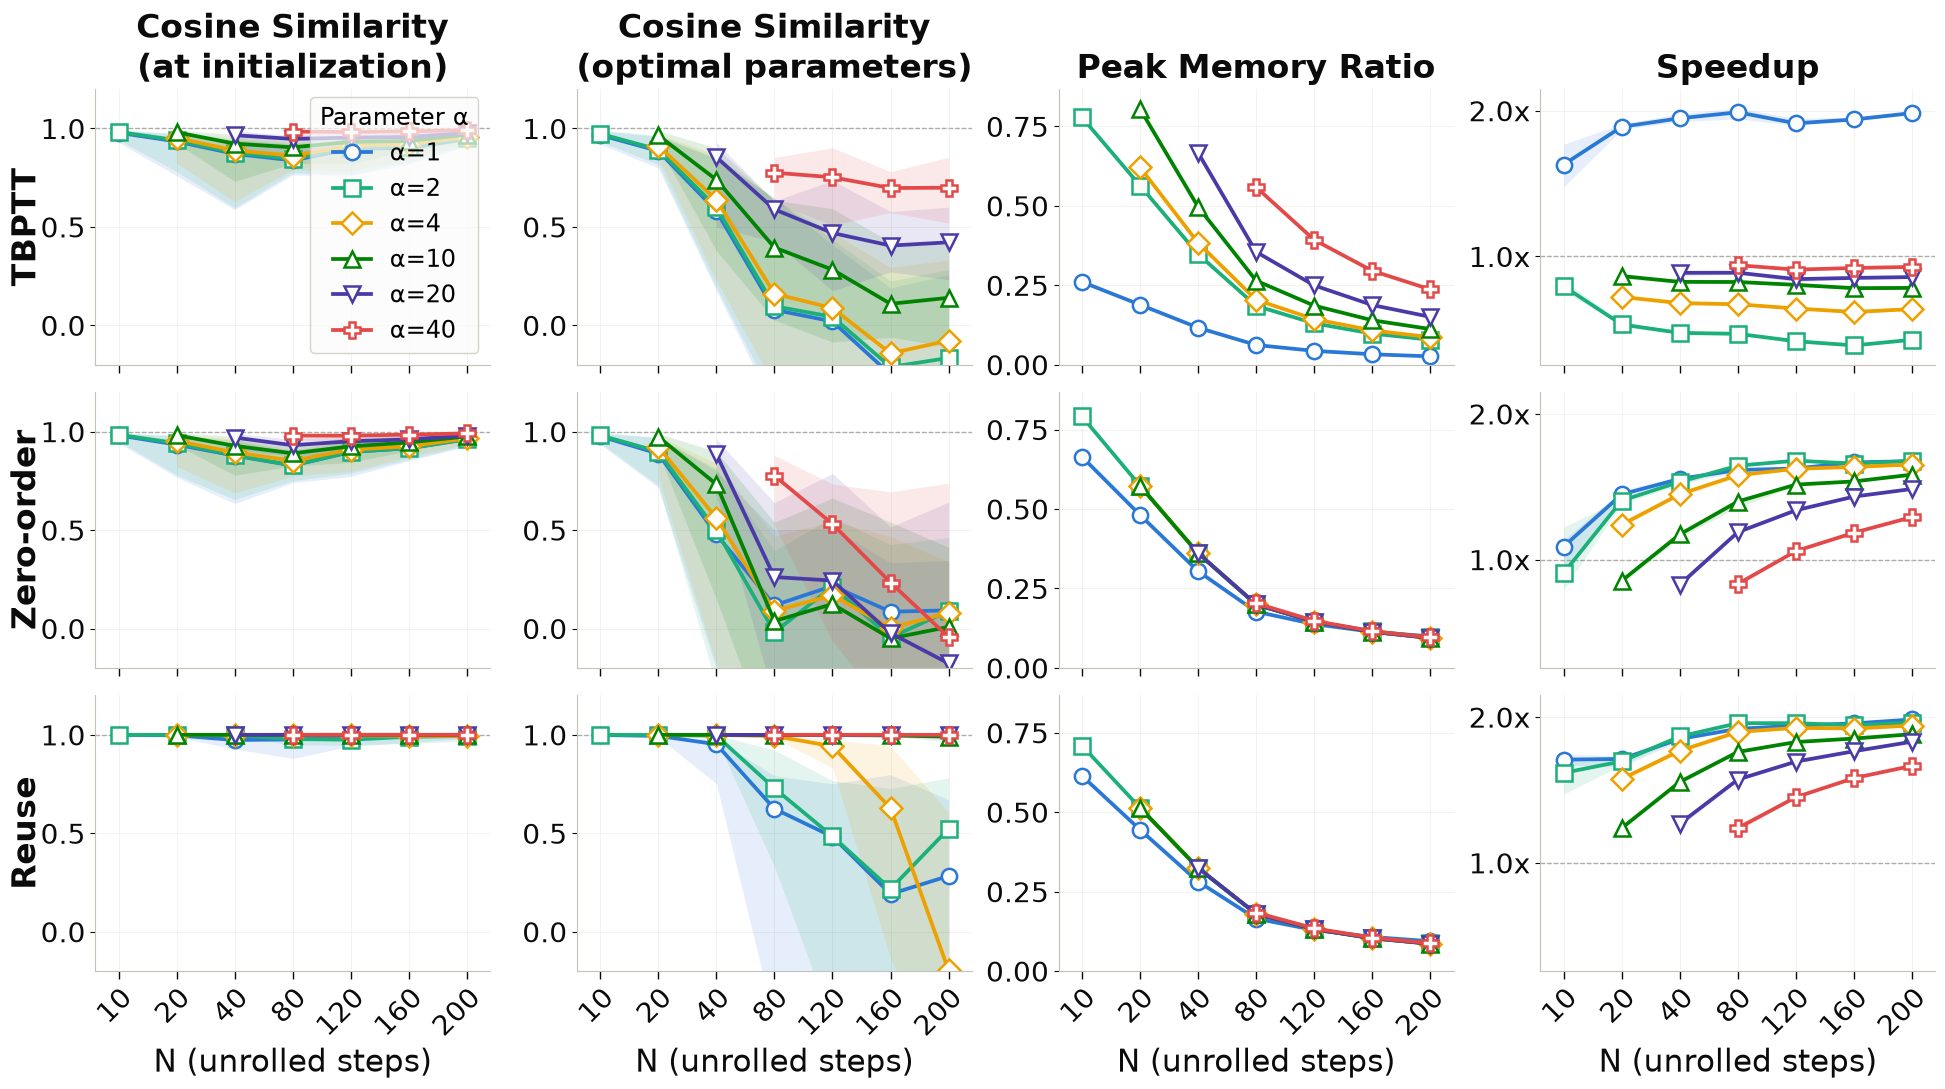

In [11]:
# Load results
df_fidelity = pd.read_pickle(RESULTS_DIR / f"fidelity_benchmark_{N_ICS}_ics.pkl")

plot_fidelity_benchmark(
    df_fidelity,
    method_names=("TBPTT", "Zero-order", "Reuse"),
    save_path=PLOT_PATH,
)